#### Prophet Forecasting

**What is Prophet?** A forecasting tool made by Facebook (Meta). It splits a series into
**trend + yearly pattern + weekly pattern + holidays**. It is good at seasonality, which is
exactly what AQI has (high in winter, low in monsoon).

**Festivals:** we tell Prophet the dates of Diwali and Holi, so it can learn their effect.

**Fair comparison:** same split as ARIMA (last 28 days for testing), same 7-day rolling forecast,
same metrics (RMSE, MAE) and the same naive baseline.

In [1]:
import logging, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet

In [2]:
warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)
logging.getLogger("prophet").setLevel(logging.ERROR)

In [3]:
clean = pd.read_csv("../01_Data/processed/cleaned_data.csv", parse_dates=["Date"])
MAIN = ["Delhi", "Lucknow", "Bengaluru", "Chennai", "Hyderabad"]
TEST_DAYS = 28

In [4]:
def get_series(city):
    s = clean[clean["City"] == city].set_index("Date")["AQI"].sort_index()
    s = s.asfreq("D").interpolate(limit=7)
    missing = s.isna()
    if missing.any():
        s = s.loc[missing[missing].index.max() + pd.Timedelta(days=1):]
    s = s.asfreq("D")
    s.index = pd.DatetimeIndex(s.index, freq="D")
    return s

In [5]:
def metrics(actual, pred):
    err = actual - pred
    return {"RMSE": round(float(np.sqrt((err ** 2).mean())), 1),
            "MAE": round(float(err.abs().mean()), 1)}

def naive_forecast(train, test, horizon=7):
    last, preds = train.iloc[-1], []
    for i in range(0, len(test), horizon):
        chunk = test.iloc[i:i + horizon]
        preds.append(pd.Series(last, index=chunk.index))
        last = chunk.iloc[-1]
    return pd.concat(preds)

Diwali and Holi are given as holidays. lower_window and upper_window extend the effect to the days around the festival.

In [6]:
diwali = ["2015-11-11", "2016-10-30", "2017-10-19", "2018-11-07", "2019-10-27"]
holi   = ["2015-03-06", "2016-03-24", "2017-03-13", "2018-03-02", "2019-03-21", "2020-03-10"]

holidays = pd.concat([
    pd.DataFrame({"holiday": "diwali", "ds": pd.to_datetime(diwali), "lower_window": -1, "upper_window": 3}),
    pd.DataFrame({"holiday": "holi",   "ds": pd.to_datetime(holi),   "lower_window": 0,  "upper_window": 1}),
])
holidays

,holiday,ds,lower_window,upper_window
0,diwali,2015-11-11,-1,3
1,diwali,2016-10-30,-1,3
2,diwali,2017-10-19,-1,3
3,diwali,2018-11-07,-1,3
4,diwali,2019-10-27,-1,3
0,holi,2015-03-06,0,1
1,holi,2016-03-24,0,1
2,holi,2017-03-13,0,1
3,holi,2018-03-02,0,1
4,holi,2019-03-21,0,1


Same idea as ARIMA: forecast 7 days, then reveal the real 7 days and repeat 4 times. Prophet is retrained each time on all data available up to that day.

In [7]:
def prophet_rolling(s, test_days=TEST_DAYS, horizon=7):
    tr, te = s.iloc[:-test_days], s.iloc[-test_days:]
    history, preds = tr.copy(), []
    for i in range(0, len(te), horizon):
        chunk = te.iloc[i:i + horizon]
        d = history.reset_index()
        d.columns = ["ds", "y"]
        m = Prophet(yearly_seasonality=True, weekly_seasonality=True,
                    daily_seasonality=False, holidays=holidays)
        m.fit(d)
        yhat = m.predict(pd.DataFrame({"ds": chunk.index}))["yhat"].values
        preds.append(pd.Series(np.clip(yhat, 0, None), index=chunk.index))
        history = pd.concat([history, chunk])
    return pd.concat(preds), tr, te

Delhi test

23:52:00 - cmdstanpy - INFO - Chain [1] start processing
23:52:01 - cmdstanpy - INFO - Chain [1] done processing
23:52:01 - cmdstanpy - INFO - Chain [1] start processing
23:52:01 - cmdstanpy - INFO - Chain [1] done processing
23:52:01 - cmdstanpy - INFO - Chain [1] start processing
23:52:02 - cmdstanpy - INFO - Chain [1] done processing
23:52:02 - cmdstanpy - INFO - Chain [1] start processing
23:52:02 - cmdstanpy - INFO - Chain [1] done processing


Prophet: {'RMSE': 49.0, 'MAE': 31.0}
Naive  : {'RMSE': 46.0, 'MAE': 30.6}


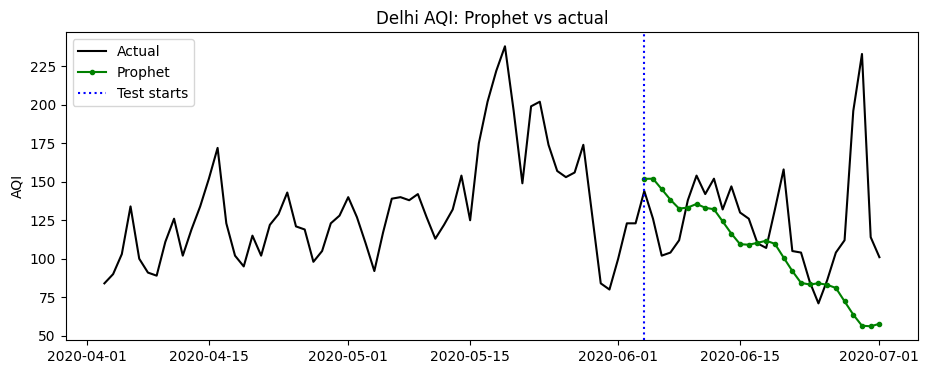

In [8]:
delhi = get_series("Delhi")
pred_p, tr, te = prophet_rolling(delhi)
print("Prophet:", metrics(te, pred_p))
print("Naive  :", metrics(te, naive_forecast(tr, te)))

plt.figure(figsize=(11, 4))
plt.plot(delhi.iloc[-90:], label="Actual", color="black")
plt.plot(pred_p, label="Prophet", color="green", marker="o", markersize=3)
plt.axvline(te.index.min(), color="blue", linestyle=":", label="Test starts")
plt.title("Delhi AQI: Prophet vs actual")
plt.ylabel("AQI")
plt.legend()
plt.show()

We run Prophet for all cities and put it next to ARIMA and the naive baseline in one table.

In [9]:
rows = []
for city in MAIN:
    try:
        s = get_series(city)
        print(city, "|", len(s), "days")
        if len(s) < 365:
            print("   Skipped: less than 1 year of data")
            continue
        p, tr, te = prophet_rolling(s)
        m, mn = metrics(te, p), metrics(te, naive_forecast(tr, te))
        rows.append({"City": city, "Prophet_RMSE": m["RMSE"], "Prophet_MAE": m["MAE"],
                     "Naive_RMSE": mn["RMSE"]})
        print("   done")
    except Exception as e:
        print("   FAILED:", type(e).__name__, "-", str(e)[:150])

prophet_results = pd.DataFrame(rows)
prophet_results.to_csv("../01_Data/processed/prophet_results.csv", index=False)

arima = pd.read_csv("../01_Data/processed/arima_results.csv")[["City", "RMSE", "MAE"]]
arima.columns = ["City", "ARIMA_RMSE", "ARIMA_MAE"]
comparison = prophet_results.merge(arima, on="City", how="left")
comparison = comparison[["City", "Naive_RMSE", "ARIMA_RMSE", "Prophet_RMSE", "ARIMA_MAE", "Prophet_MAE"]]
comparison

Delhi | 2009 days


23:52:19 - cmdstanpy - INFO - Chain [1] start processing
23:52:19 - cmdstanpy - INFO - Chain [1] done processing
23:52:20 - cmdstanpy - INFO - Chain [1] start processing
23:52:20 - cmdstanpy - INFO - Chain [1] done processing
23:52:20 - cmdstanpy - INFO - Chain [1] start processing
23:52:20 - cmdstanpy - INFO - Chain [1] done processing
23:52:21 - cmdstanpy - INFO - Chain [1] start processing
23:52:21 - cmdstanpy - INFO - Chain [1] done processing
23:52:21 - cmdstanpy - INFO - Chain [1] start processing


   done
Lucknow | 1497 days


23:52:21 - cmdstanpy - INFO - Chain [1] done processing
23:52:21 - cmdstanpy - INFO - Chain [1] start processing
23:52:22 - cmdstanpy - INFO - Chain [1] done processing
23:52:22 - cmdstanpy - INFO - Chain [1] start processing
23:52:22 - cmdstanpy - INFO - Chain [1] done processing
23:52:22 - cmdstanpy - INFO - Chain [1] start processing
23:52:22 - cmdstanpy - INFO - Chain [1] done processing


   done
Bengaluru | 1930 days


...

23:52:25 - cmdstanpy - INFO - Chain [1] done processing
23:52:25 - cmdstanpy - INFO - Chain [1] start processing
23:52:25 - cmdstanpy - INFO - Chain [1] done processing
23:52:26 - cmdstanpy - INFO - Chain [1] start processing
23:52:26 - cmdstanpy - INFO - Chain [1] done processing
23:52:26 - cmdstanpy - INFO - Chain [1] start processing
23:52:26 - cmdstanpy - INFO - Chain [1] done processing
23:52:26 - cmdstanpy - INFO - Chain [1] start processing


   done
Hyderabad | 1399 days


23:52:27 - cmdstanpy - INFO - Chain [1] done processing
23:52:27 - cmdstanpy - INFO - Chain [1] start processing
23:52:27 - cmdstanpy - INFO - Chain [1] done processing
23:52:27 - cmdstanpy - INFO - Chain [1] start processing
23:52:27 - cmdstanpy - INFO - Chain [1] done processing
23:52:28 - cmdstanpy - INFO - Chain [1] start processing
23:52:28 - cmdstanpy - INFO - Chain [1] done processing


   done


,City,Naive_RMSE,ARIMA_RMSE,Prophet_RMSE,ARIMA_MAE,Prophet_MAE
0,Delhi,46.0,37.6,49.0,27.0,31.0
1,Lucknow,51.3,39.9,42.7,35.9,31.5
2,Bengaluru,13.2,13.2,15.2,11.4,12.7
3,Chennai,26.6,23.9,41.4,15.8,35.4
4,Hyderabad,15.2,16.3,22.1,12.6,18.6


## Summary of Notebook 5
- Prophet was trained with yearly and weekly seasonality plus Diwali and Holi as holidays.
- It was tested the same way as ARIMA (last 28 days, 7-day rolling forecast).
- Prophet RMSE for Delhi = ____ (ARIMA = ____, Naive = ____).
- Prophet was better / worse than ARIMA in ___ of 5 cities.

**Next step (Notebook 6):** LSTM and the final comparison of all models.